# Video 4: A real biological result

Notes for this notebook.

This notebook generates the visuals for the fourth video in the Multimodal Spatial Biology series. Here we use the per cell quantification table built in the previous video to look at a real biological pattern, immune infiltration in this liver tumor core, and put it in context against tissue morphology and a hepatocyte marker.

This notebook reuses the quantification table saved by the Video 3 notebook, so run that one first if you have not already. All output images are saved into outputs/video4, next to this notebook. That folder is also where the slide deck for this video will be placed.


In [1]:
%matplotlib inline

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


## Load the quantification table and a tissue background

We already computed per cell protein and transcript values in the Video 3 notebook and saved them to a CSV. Rather than repeating that full load and quantification step here, we simply read that CSV back in.

We do reload the COMET DAPI channel here, since we want to show marker expression on top of real tissue context rather than as a bare scatter plot with no reference. This is a quick, partial load, only COMET, so it stays fast.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from unumlocalia.io import DatasetLoader

core_id = "core01_hcc"

quant_path = Path("outputs/video3") / f"{core_id}_quantification.csv"
df_cells = pd.read_csv(quant_path)
print("Loaded quantification table:", df_cells.shape)

loader = DatasetLoader(str(Path("data/UnumLocalia"))).load(
    do_load_transcripts=False,
    load_boundaries=False,
    load_he=False,
    load_comet=True,
)

markers = loader.comet_markers[core_id]
comet_dapi = loader.get_comet_channel(core_id, markers.index("DAPI"))
print("COMET DAPI shape:", comet_dapi.shape)


Loaded quantification table: (8283, 5022)
COMET DAPI shape: (4088, 4116)


In [4]:
%matplotlib inline

## Immune infiltration, CD45

CD45 is a pan immune marker, present on nearly all white blood cells and largely absent from hepatocytes. Plotting CD45 intensity per cell, on top of the DAPI channel for tissue context, lets us see where immune cells are concentrated within this tumor core, rather than assuming they are evenly spread throughout.


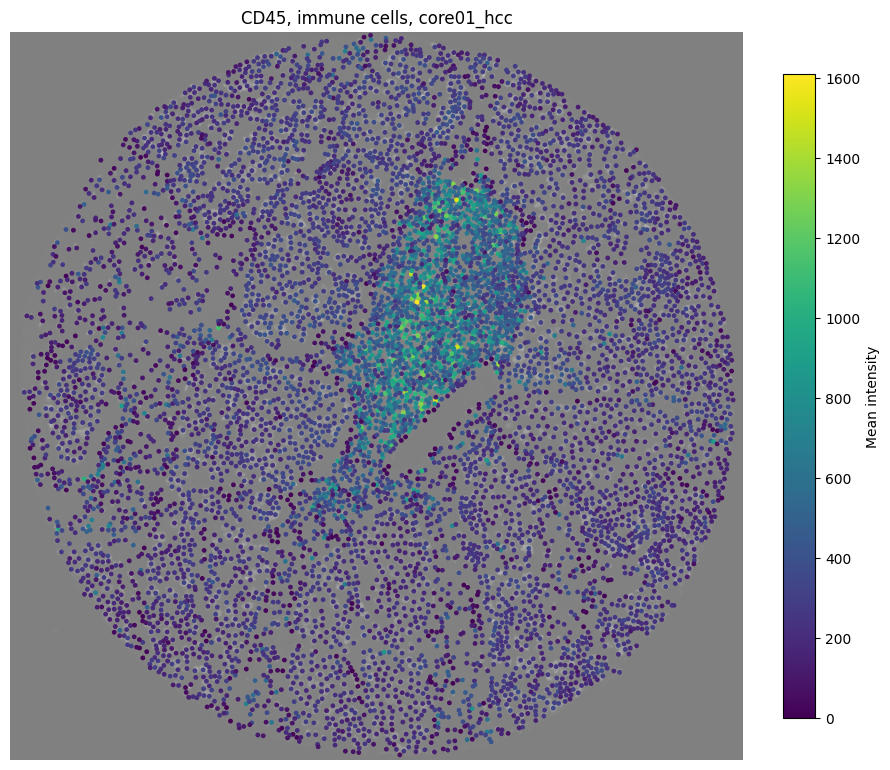

Saved slide_cd45_spatial.png


In [5]:
def plot_marker_on_tissue(df_cells, background, marker_col, title, save_name, cmap="viridis"):
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.imshow(background, cmap="gray", alpha=0.5)
    sc = ax.scatter(
        df_cells["centroid_x"],
        df_cells["centroid_y"],
        c=df_cells[marker_col],
        cmap=cmap,
        s=6,
    )
    ax.set_xlim(0, background.shape[1])
    ax.set_ylim(background.shape[0], 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.colorbar(sc, ax=ax, label="Mean intensity", fraction=0.04)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / save_name, dpi=200, facecolor="white")
    plt.show()
    print(f"Saved {save_name}")


plot_marker_on_tissue(
    df_cells, comet_dapi, "CD45 - TRITC_mean",
    "CD45, immune cells, core01_hcc",
    "slide_cd45_spatial.png",
)


## Hepatocytes, HepPar1

HepPar1 marks hepatocytes, the main functional liver cell type. In tumor tissue, we expect HepPar1 to be strong in the surrounding tumor and non tumor liver cells, and notably absent wherever the immune aggregate sits, since immune cells are not hepatocytes. This gives us a useful contrast against the CD45 result above.


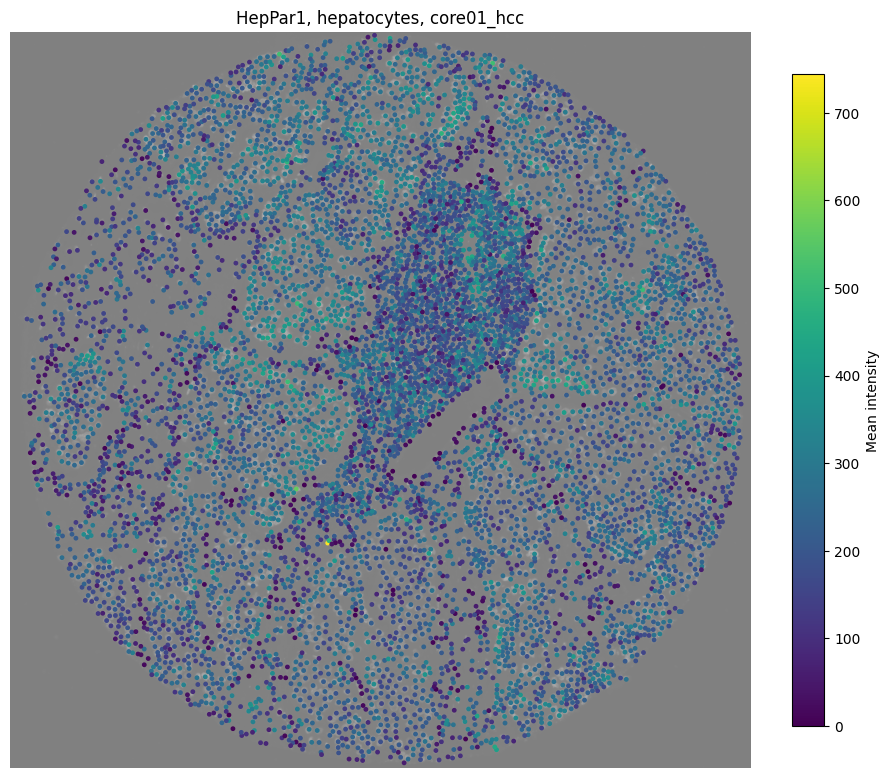

Saved slide_heppar1_spatial.png


In [6]:
plot_marker_on_tissue(
    df_cells, comet_dapi, "HepPar1 - TRITC_mean",
    "HepPar1, hepatocytes, core01_hcc",
    "slide_heppar1_spatial.png",
)


## Putting markers side by side

A single marker tells us where one cell type sits. Looking at a few markers together gives a fuller picture of tissue composition. Here we compare CD45 for immune cells, HepPar1 for hepatocytes, and alpha smooth muscle actin, a marker for stromal and vascular cells, side by side on the same tissue.


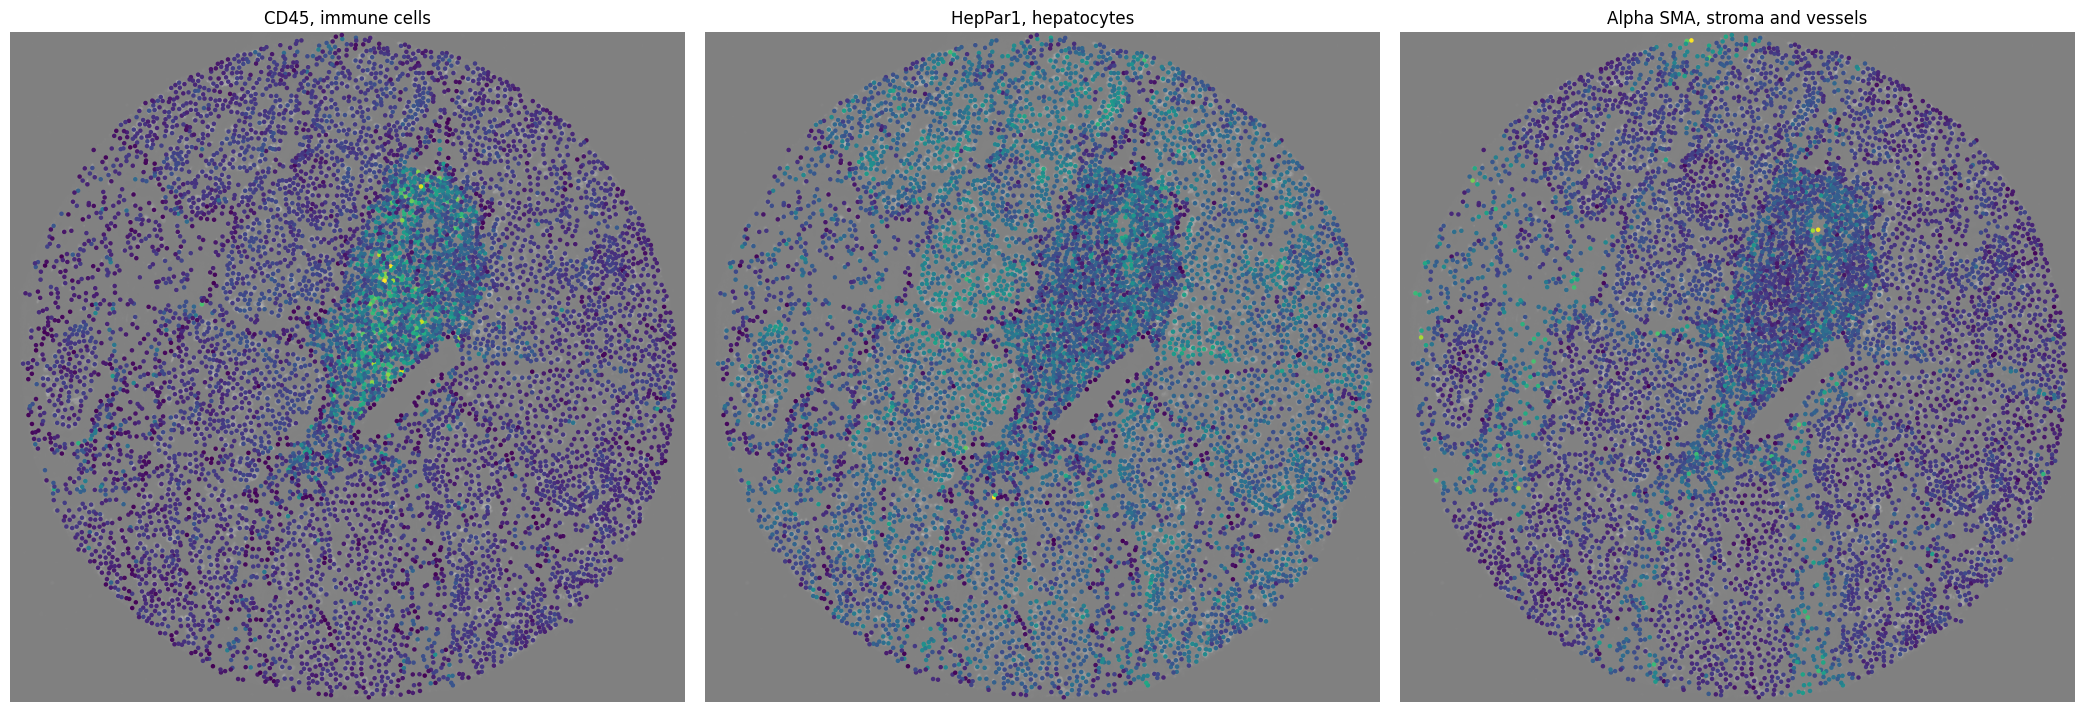

Saved slide_marker_panel_comparison.png


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

marker_panels = [
    ("CD45 - TRITC_mean", "CD45, immune cells"),
    ("HepPar1 - TRITC_mean", "HepPar1, hepatocytes"),
    ("αSMA - TRITC_mean", "Alpha SMA, stroma and vessels"),
]

for ax, (col, title) in zip(axes, marker_panels):
    ax.imshow(comet_dapi, cmap="gray", alpha=0.5)
    sc = ax.scatter(df_cells["centroid_x"], df_cells["centroid_y"], c=df_cells[col], cmap="viridis", s=5)
    ax.set_xlim(0, comet_dapi.shape[1])
    ax.set_ylim(comet_dapi.shape[0], 0)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_marker_panel_comparison.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_marker_panel_comparison.png")


## Summary

Looking at CD45, HepPar1, and alpha SMA together on the same tissue gives us a real, data driven picture of tissue composition in this tumor core. The dense immune aggregate we first noticed in the registration overlay turns out to be a genuine CD45 high region, distinct from the surrounding HepPar1 high tumor tissue, with stromal signal marking the structural boundary between them.

Next episode, we repeat this same pipeline, registration, segmentation, quantification, on the non tumor liver core, and compare the two directly to see how immune composition differs between diseased and healthy tissue.
